# Perceptron

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

In [10]:
# Perceptron class
class Perceptron:
    def __init__(self, threshold = 0.0, eta0 = 0.1, random_state=42):
        self.eta0 = eta0
        self.weights = None
        self.rng = np.random.default_rng(seed=random_state)
        self.bias = self.rng.random()

    def fit(self, X, y, epochs = 1):
        if self.weights == None or self.weights.shape[0] != X.shape[1]:
            self.weights = self.rng.standard_normal(size=(X.shape[1], 1))

        for _ in range(epochs):
            for x_row, y_val in zip(X, y):
                weighted_sum = self.compute_weighted_sum(x_row)
                y_pred = self.compute_class(weighted_sum)

                for i, x in enumerate(x_row):
                    self.weights[i] = self.weights[i] + self.eta0 * (y_val - y_pred) * x
                self.bias = self.bias + self.eta0 * (y_val - y_pred)

    def predict(self, X):
        y_pred = []
        for i, x_row in enumerate(X):
            weighted_sum = self.compute_weighted_sum(x_row)
            y_pred.append(self.compute_class(weighted_sum))

        return np.array(y_pred)

    def compute_weighted_sum(self, x_row):
        return ((x_row.reshape((x_row.shape[0], 1)) * self.weights).sum(axis=0)).item() + self.bias

    def compute_class(self, weighted_sum):
        return 1 if weighted_sum >= 0 else 0
            

In [11]:
X, y = make_classification(
    n_samples=100,
    n_features=3,
    n_informative=3,
    n_repeated=0,
    n_redundant=0
)

y = y.reshape((y.shape[0], 1))

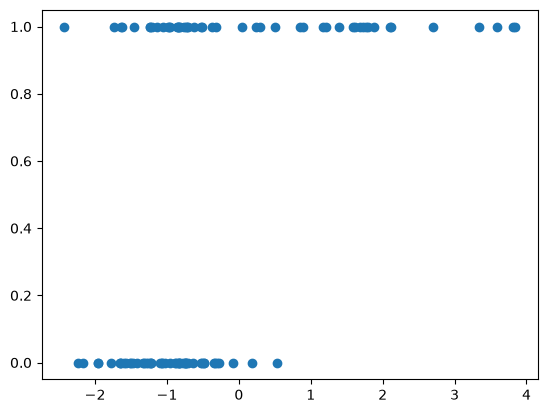

In [12]:
plt.figure()
plt.scatter(X[:, 0], y, label='test')
plt.show()

In [13]:
X_train, X_test, y_train, y_test =  train_test_split(X, y, random_state=42)

In [14]:
pct = Perceptron()

In [15]:
pct.fit(X_train, y_train)

In [16]:
y_pred = pct.predict(X_test)

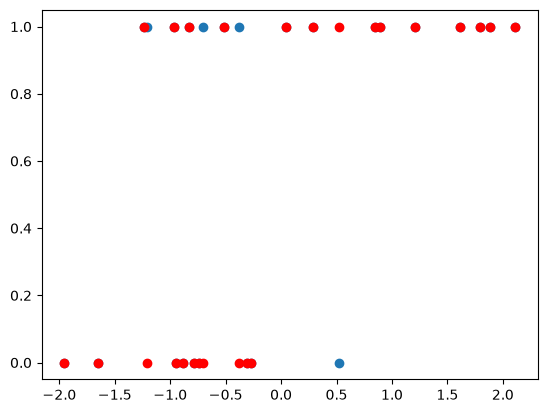

In [17]:
plt.figure()
plt.scatter(X_test[:, 0], y_test)
plt.scatter(X_test[:, 0], y_pred, c='red')